# Scoring de credito: quien no paga y por que

**Que responde este cuaderno**

1. Cual es la tasa de impago de la cartera.
2. Como cambia el riesgo segun el estado de la cuenta, el proposito y el historial.
3. Que variables pesan mas en un modelo simple, en odds ratio.
4. Cuanto discrimina el modelo (AUC) y donde se equivoca.
5. Como mueven el riesgo el plazo y el monto.

**Datos**: `german_credit_cleaned.csv` (1.000 creditos, dataset German Credit). Se descarga por URL al ejecutar: no hace falta subir nada.

**Como correrlo**: Runtime > Run all. pandas, matplotlib y scikit-learn.

In [1]:
import io, pathlib, urllib.request
import pandas as pd
import matplotlib.pyplot as plt

BASE = 'https://raw.githubusercontent.com/Nicolenki7/German_Credit_Scoring_Data/main/'
pathlib.Path('outputs').mkdir(exist_ok=True)

with urllib.request.urlopen(BASE + 'german_credit_cleaned.csv') as r:
    df = pd.read_csv(io.BytesIO(r.read()))

print('filas:', len(df), '| columnas:', len(df.columns))
print('objetivo:', df['target'].value_counts().to_dict())
df.head(3)

filas: 1000 | columnas: 21
objetivo: {'good': 700, 'bad': 300}


,checking_acc_status,duration,cred_hist,purpose,loan_amt,saving_acc_bonds,present_employment_since,installment_rate,personal_stat_gender,other_debtors_guarantors,...,property,age,other_installment_plans,housing,num_curr_loans,job,num_people_provide_maint,telephone,is_foreign_worker,target
0,below_0,6,risky_acc_or_curr_loan_other,radio_tv,1169,unknown_no_saving_acc,above_7y,4,male:single,none,...,real_estate,67,none,own,2,skilled_official,1,yes,yes,good
1,below_200,48,curr_loans_paid_duly,radio_tv,5951,below_100,below_4y,2,female:divorced_or_married,none,...,real_estate,22,none,own,1,skilled_official,1,no,yes,bad
2,no_cheking_acc,12,risky_acc_or_curr_loan_other,education,2096,below_100,below_7y,2,male:single,none,...,real_estate,49,none,own,1,unskilled_resident,2,no,yes,good


## 1. Tasa de impago

La linea base del negocio: cualquier modelo tiene que mejorarla.

In [2]:
impago = (df['target'] == 'bad').mean() * 100
ratio = (df['target'] == 'good').sum() / (df['target'] == 'bad').sum()
print(f'RESPUESTA: el {impago:.1f} % de los {len(df)} creditos termina en impago, {ratio:.2f} buenos por cada malo.')

RESPUESTA: el 30.0 % de los 1000 creditos termina en impago, 2.33 buenos por cada malo.


## 2. Donde esta el riesgo

Comparamos categorias con 30 o mas creditos, para que la diferencia no sea ruido de muestra.

In [3]:
def tasa_por(col, min_n=30):
    g = df.groupby(col)['target'].agg(n='count', impago=lambda s: (s == 'bad').mean() * 100)
    g = g[g['n'] >= min_n].sort_values('impago', ascending=False)
    g['impago'] = g['impago'].round(1)
    return g

for col in ['checking_acc_status', 'purpose', 'cred_hist']:
    print('==', col)
    print(tasa_por(col).head(6).to_string())
    print()

print(f'RESPUESTA: la media es {impago:.1f} % y el estado de la cuenta corriente es lo que mas separa: sus peores categorias casi duplican la media.')

== checking_acc_status
                       n  impago
checking_acc_status             
below_0              274    49.3
below_200            269    39.0
above:200             63    22.2
no_cheking_acc       394    11.7

== purpose
                       n  impago
purpose                         
education             50    44.0
car_new              234    38.0
business              97    35.1
furniture_equipment  181    32.0
radio_tv             280    22.1
car_used             103    16.5

== cred_hist
                                n  impago
cred_hist                                
no_loan_or_paid_duly_other     40    62.5
paid_duly_this_bank            49    57.1
curr_loans_paid_duly          530    31.9
delay_in_past                  88    31.8
risky_acc_or_curr_loan_other  293    17.1

RESPUESTA: la media es 30.0 % y el estado de la cuenta corriente es lo que mas separa: sus peores categorias casi duplican la media.


## 3. Que pesa en el modelo

Regresion logistica con one-hot para categoricas y estandarizado para numericas. Los coeficientes se convierten a **odds ratio**: por encima de 1 sube el riesgo de impago, por debajo lo baja.

In [4]:
import math
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns=['target'])
y = (df['target'] == 'bad').astype(int)
cat = X.select_dtypes(include='object').columns.tolist()
num = [c for c in X.columns if c not in cat]

prep = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
    ('num', StandardScaler(), num),
])
modelo = Pipeline([('prep', prep), ('clf', LogisticRegression(max_iter=2000, random_state=42))])
modelo.fit(X, y)

nombres = modelo.named_steps['prep'].get_feature_names_out()
coefs = modelo.named_steps['clf'].coef_[0]
pesos = pd.DataFrame({'variable': nombres, 'odds_ratio': [round(math.exp(v), 2) for v in coefs]})
pesos = pesos.sort_values('odds_ratio', ascending=False).reset_index(drop=True)
pesos.to_csv('outputs/odds_ratios.csv', index=False)

print('Suben el riesgo:')
print(pesos.head(8).to_string(index=False))
print()
print('Lo bajan:')
print(pesos.tail(5).to_string(index=False))
print()
primero = pesos['variable'].iloc[0]
print(f'RESPUESTA: la variable con mas peso al alza es {primero}.')

Suben el riesgo:
                                  variable  odds_ratio
          cat__checking_acc_status_below_0        2.08
                      cat__purpose_car_new        2.05
                    cat__purpose_education        2.00
        cat__cred_hist_paid_duly_this_bank        1.83
                cat__is_foreign_worker_yes        1.78
           cat__saving_acc_bonds_below_100        1.76
cat__other_debtors_guarantors_co_applicant        1.64
 cat__cred_hist_no_loan_or_paid_duly_other        1.63

Lo bajan:
                                   variable  odds_ratio
                    cat__purpose_retraining        0.55
    cat__other_debtors_guarantors_guarantor        0.51
cat__cred_hist_risky_acc_or_curr_loan_other        0.44
                      cat__purpose_car_used        0.44
    cat__checking_acc_status_no_cheking_acc        0.40

RESPUESTA: la variable con mas peso al alza es cat__checking_acc_status_below_0.


/tmp/ipykernel_2235/2092260989.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat = X.select_dtypes(include='object').columns.tolist()


## 4. Sirve el modelo?

AUC sobre una particion reservada: mide ordenar bien el riesgo, no acertar un umbral concreto.

In [5]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
modelo.fit(X_tr, y_tr)
prob = modelo.predict_proba(X_te)[:, 1]
auc = roc_auc_score(y_te, prob)

print(f'RESPUESTA: AUC = {auc:.3f} sobre {len(y_te)} creditos reservados.')
print()
print('Matriz de confusion con umbral 0,5:')
print(confusion_matrix(y_te, (prob >= 0.5).astype(int)))
print(classification_report(y_te, (prob >= 0.5).astype(int), target_names=['paga', 'impaga']))
print('Nota honesta: con 1.000 filas el AUC varia varios puntos entre particiones; el numero de arriba es de una sola.')

RESPUESTA: AUC = 0.804 sobre 250 creditos reservados.

Matriz de confusion con umbral 0,5:
[[152  23]
 [ 34  41]]
              precision    recall  f1-score   support

        paga       0.82      0.87      0.84       175
      impaga       0.64      0.55      0.59        75

    accuracy                           0.77       250
   macro avg       0.73      0.71      0.72       250
weighted avg       0.76      0.77      0.77       250

Nota honesta: con 1.000 filas el AUC varia varios puntos entre particiones; el numero de arriba es de una sola.


## 5. Plazo y monto

Las dos variables continuas que un comite de credito mira siempre.

               n  impago
tramo_plazo             
<=12m        359    21.2
13-24m       411    29.7
25-36m       143    39.9
>36m          87    51.7

               n  impago
tramo_monto             
Q1 bajo      250    30.8
Q2           250    24.8
Q3           250    22.4
Q4 alto      250    42.0

RESPUESTA: el tramo >36m tiene 51.7 % de impago frente al 21.2 % del mejor tramo.


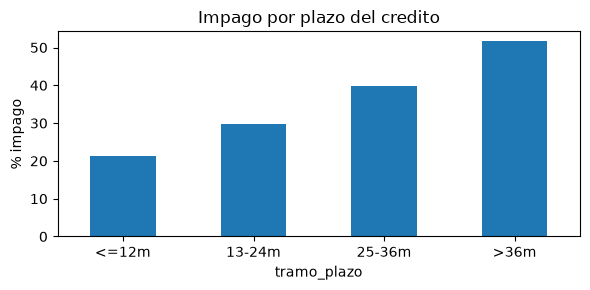

In [6]:
df['tramo_plazo'] = pd.cut(df['duration'], bins=[0, 12, 24, 36, 72], labels=['<=12m', '13-24m', '25-36m', '>36m'])
df['tramo_monto'] = pd.qcut(df['loan_amt'], 4, labels=['Q1 bajo', 'Q2', 'Q3', 'Q4 alto'])

by_plazo = df.groupby('tramo_plazo', observed=True)['target'].agg(n='count', impago=lambda s: round((s == 'bad').mean() * 100, 1))
by_monto = df.groupby('tramo_monto', observed=True)['target'].agg(n='count', impago=lambda s: round((s == 'bad').mean() * 100, 1))

print(by_plazo.to_string())
print()
print(by_monto.to_string())

peor_tramo = by_plazo['impago'].idxmax()
mejor_valor = by_plazo['impago'].min()
print()
print(f'RESPUESTA: el tramo {peor_tramo} tiene {by_plazo.loc[peor_tramo, "impago"]} % de impago frente al {mejor_valor} % del mejor tramo.')

ax = by_plazo['impago'].plot(kind='bar', figsize=(6, 3), rot=0)
ax.set_ylabel('% impago')
ax.set_title('Impago por plazo del credito')
plt.tight_layout()
plt.savefig('outputs/impago_por_plazo.png', dpi=150)
plt.show()

## Limites

- Dataset historico aleman de 1.000 filas: sirve para el metodo, no para decidir credito real.
- No hay coste asimetrico: negar a un buen pagador cuesta distinto que aprobar un impago.
- Sin validacion temporal ni calibracion de probabilidades.
- Las categorias vienen ya limpias; en un caso real habria que auditar esa codificacion.